In [1]:
import sys

from pathlib import Path
project_root = Path.cwd().parent    # notebooks -> project_root
sys.path.insert(0, str(project_root))
print(project_root)

from matplotlib import pyplot as plt
import numpy as np

from FenicsxModels.PoissonSolvers import PoissonCG
from FenicsxModels.FenicsxPriors import PriorSPDE

/Users/tcui0786/Work/DeepTransport/PyFInS-public


In [2]:
# import os
# import shutil

# os.environ["CC"] = "/usr/bin/clang"
# os.environ["CXX"] = "/usr/bin/clang++"
# os.environ.pop("LD", None)

# print("env CC      =", os.environ.get("CC"))
# print("env CXX     =", os.environ.get("CXX"))
# print("env LD      =", os.environ.get("LD"))
# print("SDKROOT     =", os.environ.get("SDKROOT"))
# print("CONDA_BUILD_SYSROOT =", os.environ.get("CONDA_BUILD_SYSROOT"))


In [2]:
# mesh size
Nx = 24
Ny = 24
corner_points=((0.0, 0.0), (2.0, 2.0))

# Dirichlet data
def gL(y): return 1.0 + 0.5*y
def gR(y): return - np.sin(2.0*np.pi*y) - 1.0

# observation grid
obs_n_grid = 4
obs_eps = 2.0/Nx

model = PoissonCG(corner_points, Nx, Ny, gL, gR, order=1, const_k=True, log_normal=True)
model.make_observation_operator(obs_n_grid, obs_eps)
prior = PriorSPDE(model.Kh, sigma = 1, ell = 1.0, mu = 0.0)


/var/folders/35/sjd32gz17sdgbnzs84sr2kb80000gp/T/ipykernel_98432/382424724.py:14: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


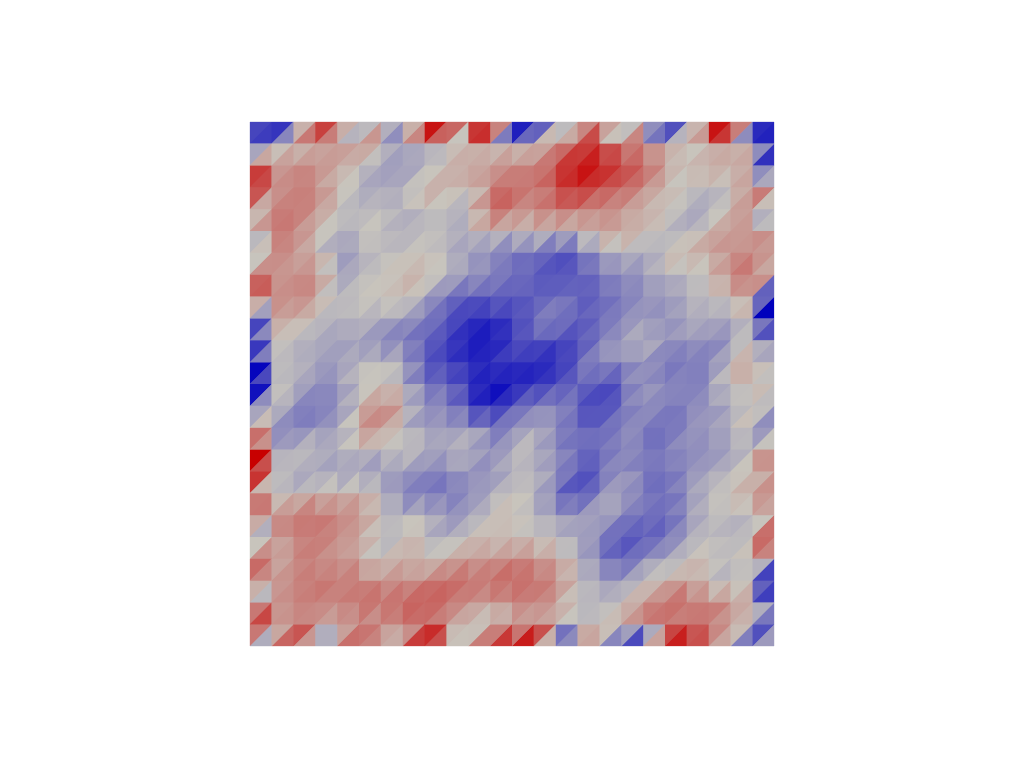

In [3]:
from dolfinx import fem
import math 
import pyvista
from FenicsxModels import Helpers

x_true = prior.sample()

plotter = pyvista.Plotter()
phi = fem.Function(prior.Kh)
phi.x.array[:] = x_true
plot_grid = Helpers.plotting_grid(phi)
plotter.add_mesh(plot_grid, show_edges=False, show_scalar_bar=False, cmap="bwr")
plotter.view_xy()
plotter.show()

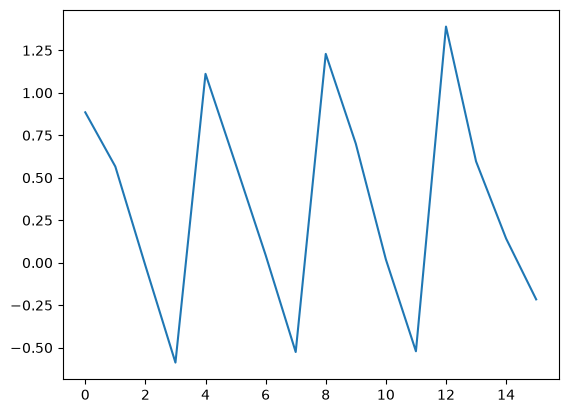

In [4]:
from BaseModels import GaussianLikelihood

y, _ = model.solve(x_true)

sig2noise = 10
sigma = np.abs(y).mean()/sig2noise
fake_data = y + np.random.normal(0, sigma, size=y.shape)
like = GaussianLikelihood(fake_data, sigma)

plt.plot(fake_data)
plt.show()

In [ ]:
from FenicsxInference import LikelihoodInformedSMC, LikelihoodInformedSubspace
from InferenceTools.TransitionKernels import OneStepKernel

kernel = OneStepKernel(
        type="OW",
        sigma=-3.0,
        adapt=True,
        nbatch=1,
)

LIS = LikelihoodInformedSubspace(prior, epsilon=0.1)

sampler = LikelihoodInformedSMC(
        prior,
        model,
        like,
        LIS,
        kernel,
        max_iter=100,
        n_samples=1000,
        n_mutation_steps=20,
        n_final_mutation_steps=10, # n_samples times the final mutation steps give the total number of samples 
        ess_tol=0.5,
        min_beta=1e-6,
        pm_sample_size=5,
)

sampler.iterate()

model+adjoint:  20%|█▉        | 199/1000 [00:05<00:20, 39.34it/s]